# Job classes and execution intervals

Run independently of the results notebook. This notebook reads the original and resampled job outputs directly. It keeps the corrected job matching, full-platform footprint contributions and half-open regional intervals.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ANALYSIS = Path.cwd() if Path.cwd().name == "analysis" else Path.cwd() / "analysis"
sys.path.insert(0, str(ANALYSIS))
from helpers import experiments, platform, load_jobs, load_signals, performance, physical_totals

FIGURES = ANALYSIS / "figures"
FIGURES.mkdir(exist_ok=True)
horizons = {"original": 35 * 86400, "resampled": 70 * 86400, "alpha-sensitivity": 35 * 86400}

from helpers import class_contributions, regional_analysis

plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 9,
        "axes.titlesize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.alpha": 0.22,
        "pdf.fonttype": 42,
        "savefig.dpi": 300,
    }
)
COLORS = {"carbon": "#2677ad", "water": "#b85d18"}
ORDER = ["mustang_slack", "mustang_stress", "trinity_slack", "trinity_stress"]
CLASSES = ["narrow-short", "other", "wide"]
CLASS_COLORS = ["#2677ad", "#a6acb1", "#b85d18"]
WORKLOAD_COLORS = dict(zip(ORDER, ["#2677ad", "#b85d18", "#568c43", "#7c5aa1"]))

## Calculate class and regional comparisons

Narrow-short jobs request at most 1% of the platform and run for at most two hours. Wide jobs request at least 10%; other replay jobs form the remaining class. Context jobs enter footprint contributions but not slowdown or weighted response time.

Each regional comparison starts after context jobs finish in both schedules and ends at the last replay submission. Six-hour boundaries are anchored at simulation time zero. Every interval excludes its right endpoint, including the final interval. Partial regions retain their actual duration. Intensity quartiles use chronological order to break ties.

The estimated gate applies one EMA update per distinct submission or completion timestamp. Both schedules are classified against this same timeline. It is descriptive: job records do not contain every scheduler call, and completions can themselves trigger updates.

In [2]:
class_rows, workload_rows, interval_rows, level_rows, gate_rows, completion_rows = (
    [],
    [],
    [],
    [],
    [],
    [],
)
for group in ["original", "resampled"]:
    config = experiments(group)
    signals = {path: load_signals(path) for path in config.environmental_trace.unique()}
    for workload, cases in config.groupby("workload"):
        machine = platform(cases.iloc[0].platform)
        source = load_jobs(group, cases.iloc[0]["name"], machine["nodes"])
        replay = source.loc[~source.is_context]
        total_work = (replay.execution_time * replay.requested_number_of_resources).sum()
        for label, jobs in replay.groupby("class"):
            work = (jobs.execution_time * jobs.requested_number_of_resources).sum()
            workload_rows.append(
                {
                    "group": group,
                    "workload": workload,
                    "class": label,
                    "jobs": len(jobs),
                    "node_hours": work / 3600,
                    "job_share_pct": 100 * len(jobs) / len(replay),
                    "work_share_pct": 100 * work / total_work,
                    "offered_load": total_work / (machine["nodes"] * 28 * 86400),
                }
            )
        for trace, cases_in_trace in cases.groupby("trace"):
            easy_exp = cases_in_trace.loc[cases_in_trace.variant == "easy_bf"].iloc[0]
            easy = load_jobs(group, easy_exp["name"], machine["nodes"])
            intensity = signals[easy_exp.environmental_trace]
            reference = performance(easy) | physical_totals(
                easy, machine, intensity, horizons[group]
            )
            for _, exp in cases_in_trace.loc[cases_in_trace.variant != "easy_bf"].iterrows():
                green = load_jobs(group, exp["name"], machine["nodes"])
                meta = {
                    "group": group,
                    "workload": workload,
                    "trace": trace,
                    "objective": exp.objective,
                }
                contributions = class_contributions(easy, green, machine)
                slowdown_delta = (
                    performance(green)["bounded_slowdown"] - reference["bounded_slowdown"]
                )
                contributions["slowdown_share_pct"] = (
                    100 * contributions.slowdown_contribution / slowdown_delta
                )
                target = "carbon_g" if exp.objective == "carbon" else "water_l"
                contributions["target_contribution_pct"] = (
                    100 * contributions[exp.objective + "_contribution"] / reference[target]
                )
                class_rows.append(contributions.assign(**meta))
                intervals, levels, gate, completions = regional_analysis(
                    easy, green, intensity[exp.objective], exp.alpha
                )
                interval_rows.append(intervals.assign(**meta))
                level_rows.append(levels.assign(**meta))
                gate_rows.append(gate.assign(**meta))
                completion_rows.append(meta | completions)
        print(group, workload)
workload_classes = pd.DataFrame(workload_rows)
contributions = pd.concat(class_rows, ignore_index=True)
intervals = pd.concat(interval_rows, ignore_index=True)
levels = pd.concat(level_rows, ignore_index=True)
gate = pd.concat(gate_rows, ignore_index=True)
completions = pd.DataFrame(completion_rows)

original mustang_slack


original mustang_stress


original trinity_slack


original trinity_stress


resampled mustang_slack


resampled mustang_stress


## Workload composition

Offered load is submitted replay node-seconds divided by platform capacity over the 28-day submission interval. It is not achieved utilization.

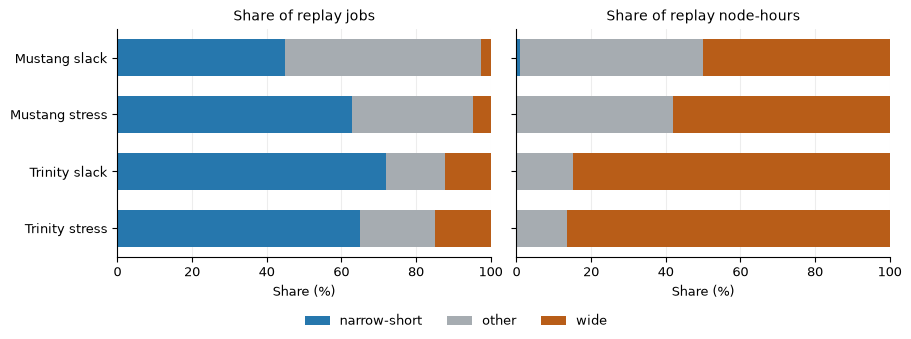

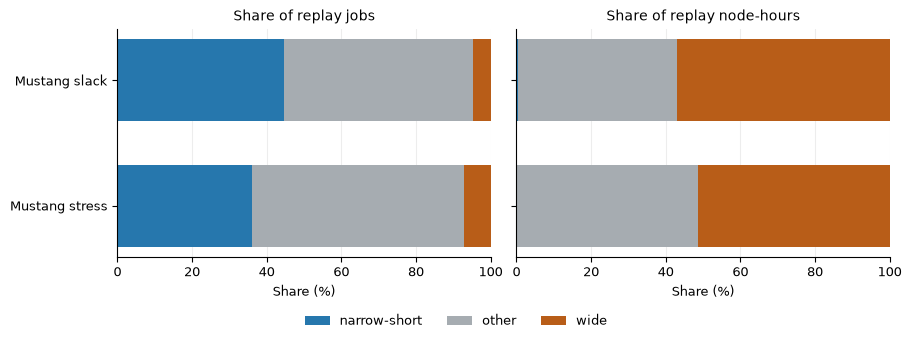

,group,workload,offered_load
0,original,mustang_slack,0.863
3,original,mustang_stress,0.972
6,original,trinity_slack,0.621
9,original,trinity_stress,0.640
12,resampled,mustang_slack,1.855
15,resampled,mustang_stress,1.739


In [3]:
for collection in ["original", "resampled"]:
    plot_data = workload_classes.loc[workload_classes.group == collection]
    order = [w for w in ORDER if w in set(plot_data.workload)]
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.3), layout="constrained", sharey=True)
    for ax, column, title in zip(
        axes,
        ["job_share_pct", "work_share_pct"],
        ["Share of replay jobs", "Share of replay node-hours"],
    ):
        left = np.zeros(len(order))
        for label, color in zip(CLASSES, CLASS_COLORS):
            values = (
                plot_data.loc[plot_data["class"] == label]
                .set_index("workload")
                .reindex(order, fill_value=0)[column]
                .to_numpy()
            )
            ax.barh(range(len(order)), values, left=left, label=label, color=color, height=0.65)
            left += values
        ax.set(title=title, xlabel="Share (%)", xlim=(0, 100))
        ax.set_yticks(range(len(order)), [s.replace("_", " ").capitalize() for s in order])
    axes[0].invert_yaxis()
    handles, labels = axes[1].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
    for suffix in ("pdf", "png"):
        fig.savefig(
            FIGURES / (f"{collection}_" + "mechanism_workload_classes" + "." + suffix),
            bbox_inches="tight",
        )
    plt.show()
display(workload_classes[["group", "workload", "offered_load"]].drop_duplicates().round(3))

## Contributions to changes from EASY

Contributions are signed and additive within each comparison. A slowdown share can be negative or exceed 100% when class effects offset each other. Medians of signed shares need not sum to 100%.

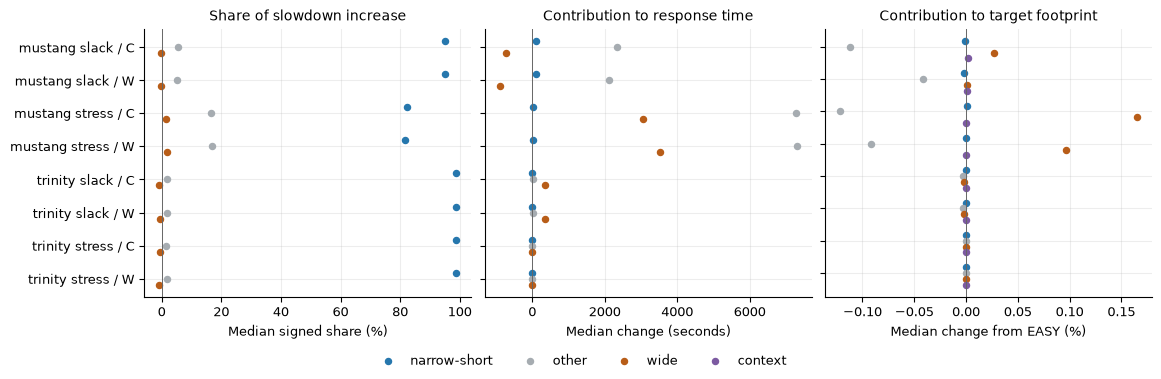

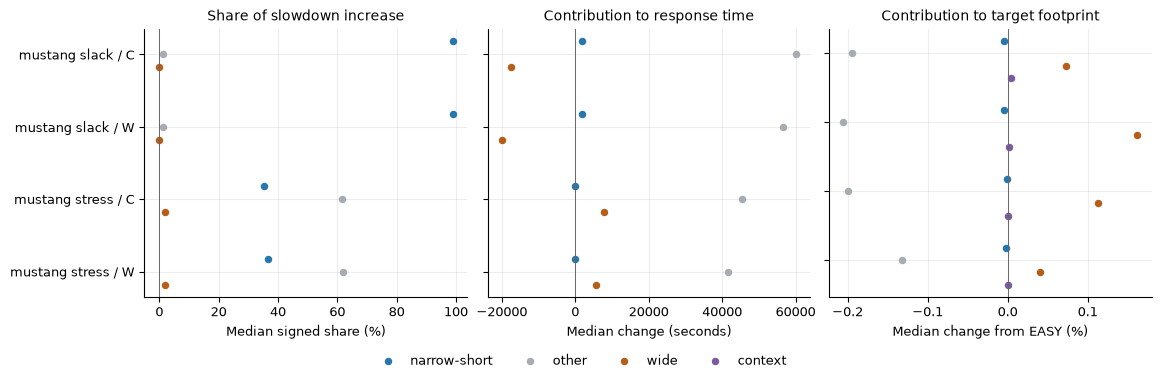

In [4]:
for collection in ["original", "resampled"]:
    plot_data = contributions.loc[contributions.group == collection]
    order = [w for w in ORDER if w in set(plot_data.workload)]
    fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.7), layout="constrained")
    columns = ["slowdown_share_pct", "wrt_contribution_seconds", "target_contribution_pct"]
    titles = [
        "Share of slowdown increase",
        "Contribution to response time",
        "Contribution to target footprint",
    ]
    units = ["Median signed share (%)", "Median change (seconds)", "Median change from EASY (%)"]
    labels = [f"{w.replace('_', ' ')} / {o[0].upper()}" for w in order for o in COLORS]
    row_count = len(labels)
    for ax, col, title, unit in zip(axes, columns, titles, units):
        plot_classes = CLASSES + (["context"] if col == "target_contribution_pct" else [])
        plot_colors = CLASS_COLORS + (["#7c5aa1"] if col == "target_contribution_pct" else [])
        for i, (label, color) in enumerate(zip(plot_classes, plot_colors)):
            vals = []
            for w in order:
                for o in COLORS:
                    subset = plot_data.loc[
                        (plot_data.workload == w)
                        & (plot_data.objective == o)
                        & (plot_data["class"] == label),
                        col,
                    ]
                    vals.append(subset.median())
            ax.scatter(vals, np.arange(row_count) + (i - 1) * 0.18, label=label, color=color, s=19)
        ax.axvline(0, color=".4", lw=0.7)
        ax.set(
            title=title,
            xlabel=unit,
            yticks=range(row_count),
            yticklabels=labels if ax == axes[0] else [""] * row_count,
        )
        ax.invert_yaxis()
    handles, labels = axes[2].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=4, frameon=False)
    for suffix in ("pdf", "png"):
        fig.savefig(
            FIGURES / (f"{collection}_" + "mechanism_class_contributions" + "." + suffix),
            bbox_inches="tight",
        )
    plt.show()

## Regional throughput

An illustrative window uses Mustang stress, Germany, 2019-02-04, carbon objective. Throughput divided by relative intensity is descriptive and is not a footprint metric.

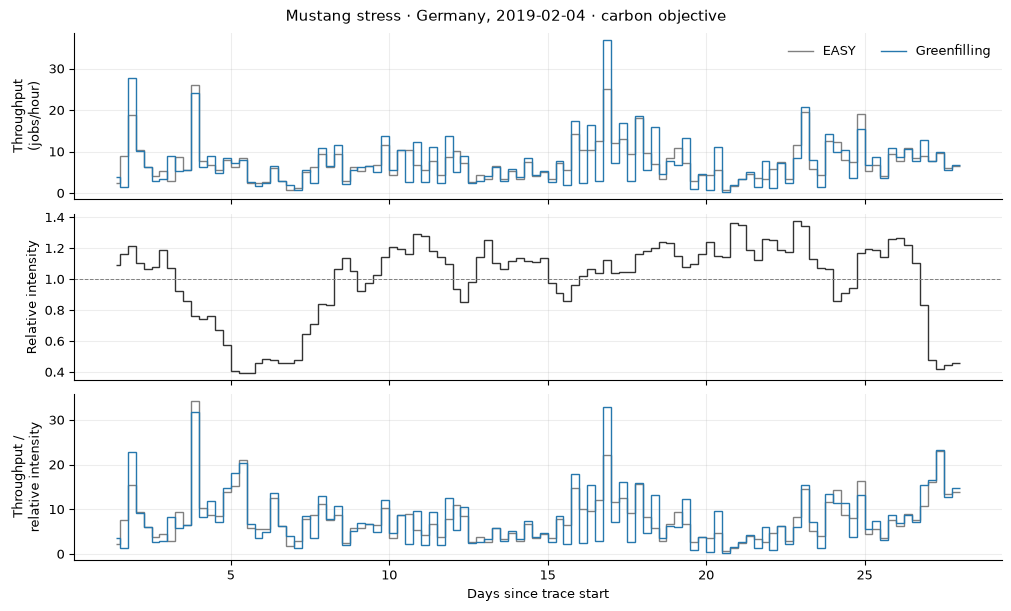

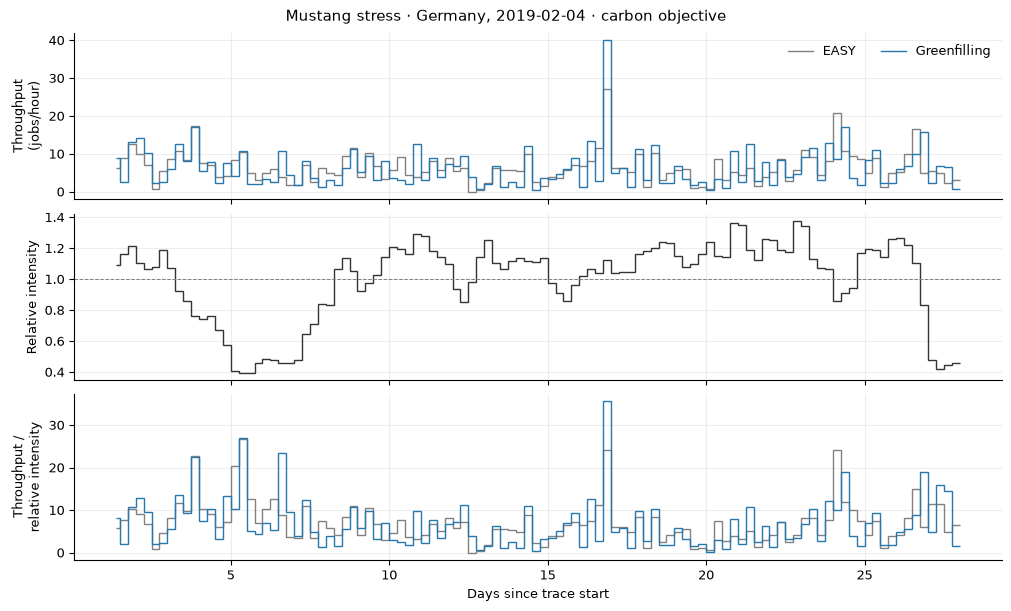

In [5]:
for collection in ["original", "resampled"]:
    plot_data = intervals.loc[intervals.group == collection]
    selected = plot_data.loc[
        (plot_data.workload == "mustang_stress")
        & (plot_data.trace == "DE_2019-02-04")
        & (plot_data.objective == "carbon")
    ].sort_values("start_seconds")
    fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True, layout="constrained")
    edges = np.r_[selected.start_seconds, selected.end_seconds.iloc[-1]] / 86400
    for name, color, label in [("easy", ".5", "EASY"), ("green", COLORS["carbon"], "Greenfilling")]:
        axes[0].stairs(
            selected[f"{name}_throughput"], edges, baseline=None, color=color, lw=1, label=label
        )
        axes[2].stairs(
            selected[f"{name}_throughput_per_relative_intensity"],
            edges,
            baseline=None,
            color=color,
            lw=1,
        )
    axes[1].stairs(selected.relative_intensity, edges, baseline=None, color=".2", lw=1)
    axes[1].axhline(1, color=".5", ls="--", lw=0.7)
    axes[0].set_ylabel("Throughput\n(jobs/hour)")
    axes[1].set_ylabel("Relative intensity")
    axes[2].set_ylabel("Throughput /\nrelative intensity")
    axes[2].set_xlabel("Days since trace start")
    axes[0].legend(loc="upper right", frameon=False, ncol=2)
    fig.suptitle("Mustang stress · Germany, 2019-02-04 · carbon objective")
    for suffix in ("pdf", "png"):
        fig.savefig(
            FIGURES / (f"{collection}_" + "mechanism_regional_timeline" + "." + suffix),
            bbox_inches="tight",
        )
    plt.show()

Quartile throughput divides pooled completion counts by pooled duration. The ratio then compares Greenfilling with EASY. Points and bars below show medians and interquartile ranges across trace windows, separately for each workload and objective.

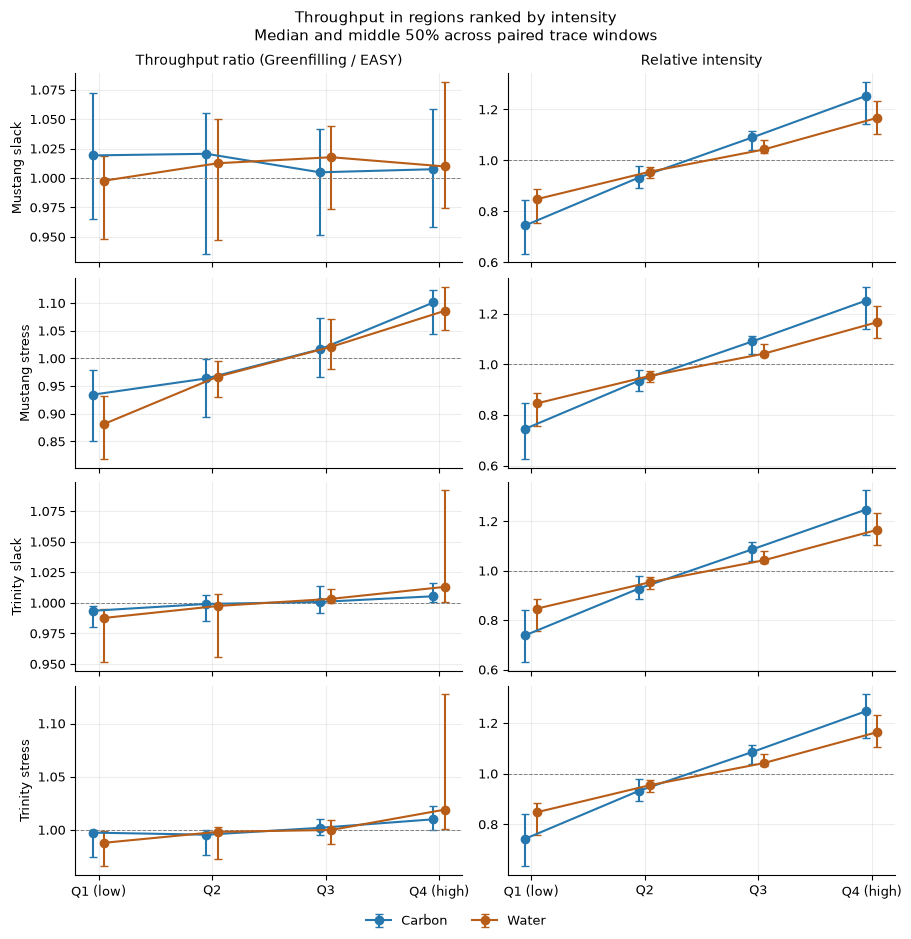

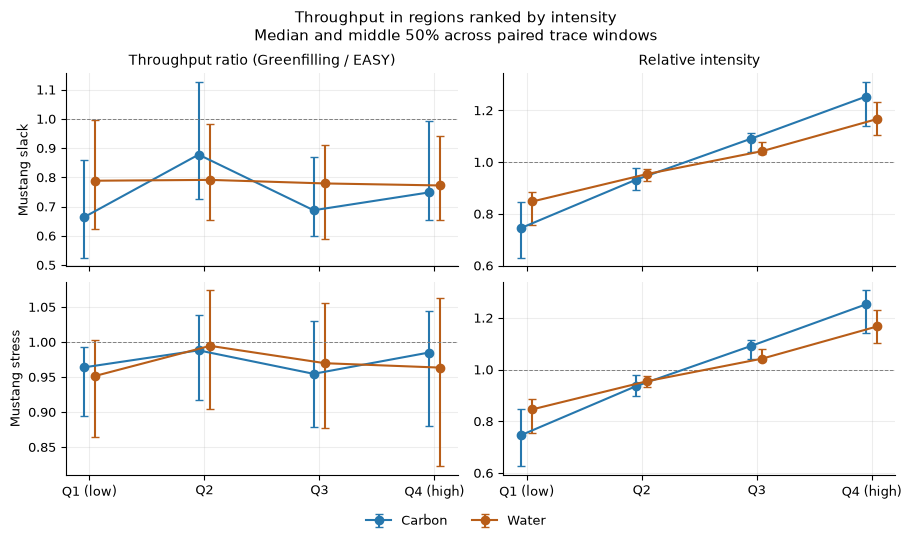

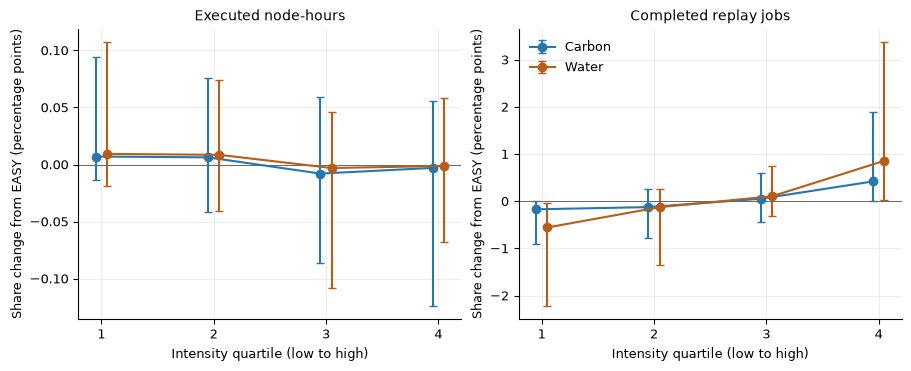

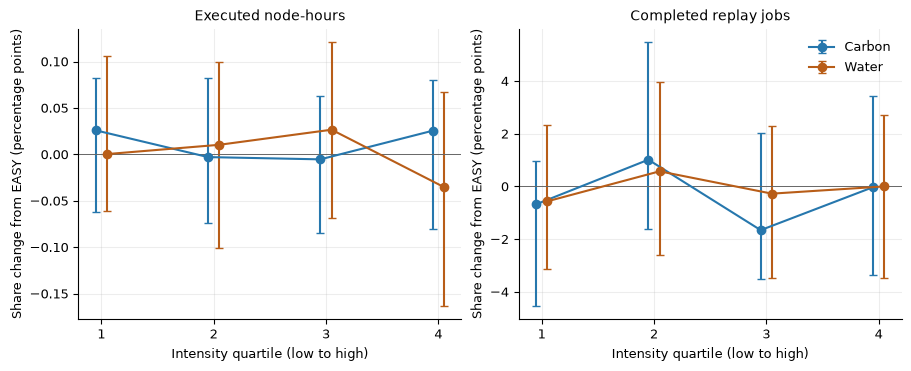

In [6]:
for collection in ["original", "resampled"]:
    plot_data = levels.loc[levels.group == collection]
    order = [w for w in ORDER if w in set(plot_data.workload)]
    fig, axes = plt.subplots(
        len(order),
        2,
        figsize=(9, 1.3 + 2 * len(order)),
        sharex=True,
        squeeze=False,
        layout="constrained",
    )
    for row, workload in enumerate(order):
        for column, metric in enumerate(("throughput_ratio", "relative_intensity")):
            ax = axes[row, column]
            for objective, offset in [("carbon", -0.05), ("water", 0.05)]:
                selected = plot_data.loc[
                    (plot_data.workload == workload) & (plot_data.objective == objective)
                ]
                grouped = selected.groupby("intensity_quartile")[metric]
                median = grouped.median().reindex([1, 2, 3, 4])
                lower = grouped.quantile(0.25).reindex([1, 2, 3, 4])
                upper = grouped.quantile(0.75).reindex([1, 2, 3, 4])
                ax.errorbar(
                    np.arange(len([1, 2, 3, 4])) + offset,
                    median,
                    yerr=[median - lower, upper - median],
                    marker="o",
                    capsize=3,
                    color=COLORS[objective],
                    label=objective.capitalize(),
                )
            ax.axhline(1, color=".5", ls="--", lw=0.7)
            ax.set_xticks(range(len([1, 2, 3, 4])), ["Q1 (low)", "Q2", "Q3", "Q4 (high)"])
            if column == 0:
                ax.set_ylabel(workload.replace("_", " ").capitalize())
            if row == 0:
                ax.set_title(
                    "Throughput ratio (Greenfilling / EASY)"
                    if column == 0
                    else "Relative intensity"
                )
    handles, legend_labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="outside lower center", frameon=False, ncol=2)
    fig.suptitle(
        "Throughput in regions ranked by intensity"
        + "\nMedian and middle 50% across paired trace windows"
    )
    for suffix in ("pdf", "png"):
        fig.savefig(
            FIGURES / (f"{collection}_" + "mechanism_regional_throughput" + "." + suffix),
            bbox_inches="tight",
        )
    plt.show()

for collection in ["original", "resampled"]:
    plot_data = levels.loc[levels.group == collection]
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained", sharex=True)
    for ax, col, title in zip(
        axes,
        ["node_hours_share_delta_pp", "completions_share_delta_pp"],
        ["Executed node-hours", "Completed replay jobs"],
    ):
        for o, offset in [("carbon", -0.05), ("water", 0.05)]:
            groups = plot_data.loc[plot_data.objective == o].groupby("intensity_quartile")[col]
            median = groups.median()
            lower = groups.quantile(0.25)
            upper = groups.quantile(0.75)
            ax.errorbar(
                median.index + offset,
                median,
                yerr=[median - lower, upper - median],
                marker="o",
                capsize=3,
                label=o.capitalize(),
                color=COLORS[o],
            )
        ax.axhline(0, color=".4", lw=0.7)
        ax.set(
            title=title,
            xlabel="Intensity quartile (low to high)",
            ylabel="Share change from EASY (percentage points)",
            xticks=[1, 2, 3, 4],
        )
    axes[1].legend(frameon=False)
    for suffix in ("pdf", "png"):
        fig.savefig(
            FIGURES / (f"{collection}_" + "mechanism_regional_execution" + "." + suffix),
            bbox_inches="tight",
        )
    plt.show()

## Estimated gate and completion intensity

Gate rates use the total duration in each state; intensity is duration-weighted. Intensity at completion describes different cohorts if the schedules complete different jobs. It does not establish a causal gate effect or replace full-platform footprint accounting.

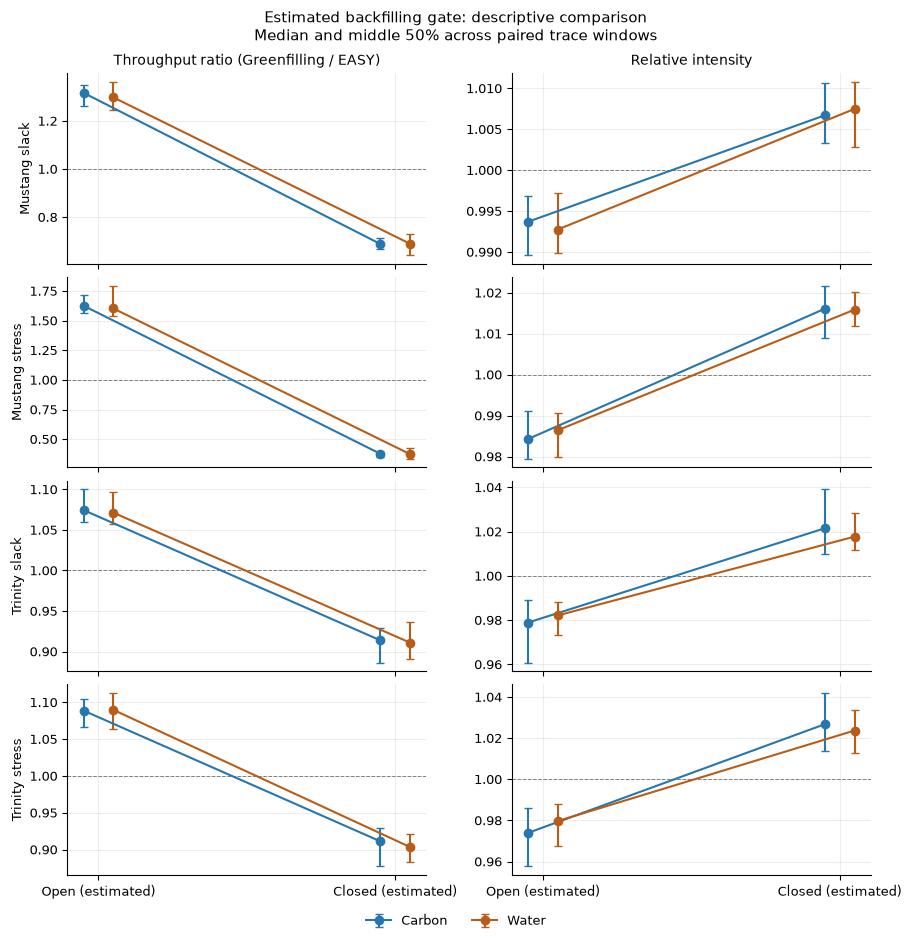

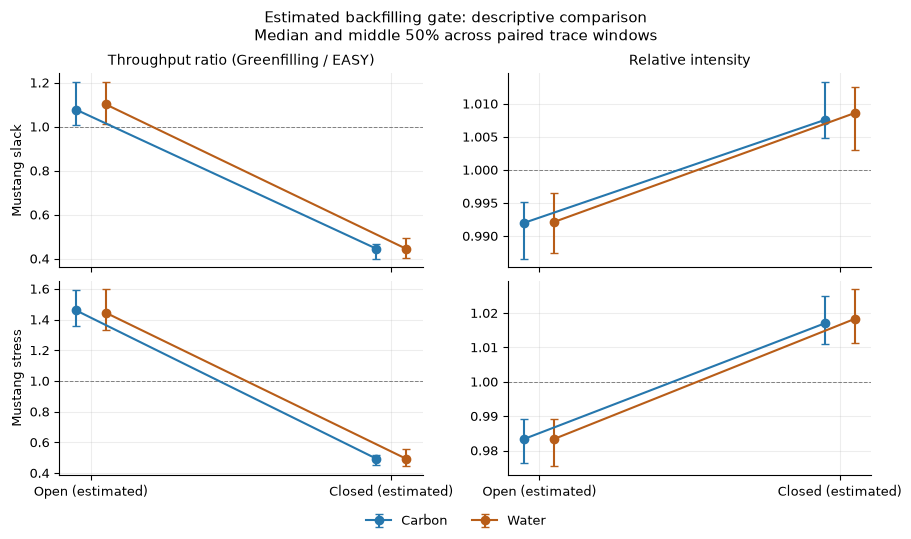

gate_state                          closed   open
group     workload       objective               
original  mustang_slack  carbon      49.17  50.83
                         water       48.33  51.67
          mustang_stress carbon      48.76  51.24
                         water       48.00  52.00
          trinity_slack  carbon      50.55  49.45
                         water       49.91  50.09
          trinity_stress carbon      49.47  50.53
                         water       48.43  51.57
resampled mustang_slack  carbon      50.26  49.74
                         water       49.51  50.49
          mustang_stress carbon      49.66  50.34
                         water       48.53  51.47

easy_completed_pct  green_completed_pct  \
group     workload       objective                                            
original  mustang_slack  carbon                 97.810               98.296   
                         water                  97.810               98.287   
          mustang_stress carbon                 92.788               92.444   
                         water                  92.788               92.474   
          trinity_slack  carbon                 99.697               99.697   
                         water                  99.697               99.697   
          trinity_stress carbon                 99.010               99.010   
                         water                  99.010               99.010   
resampled mustang_slack  carbon                 82.920               64.495   
                         water                  82.940               65.495   
          mustang_stress carbon                 78.559               75.833   
                         water                  78.559               76.035   

                                    completion_intensity_change_pct  
group     workload       objective                                   
original  mustang_slack  carbon                              -0.250  
                         water                                0.009  
          mustang_stress carbon                               0.749  
                         water                                0.700  
          trinity_slack  carbon                               0.185  
                         water                                0.316  
          trinity_stress carbon                               0.187  
                         water                                0.294  
resampled mustang_slack  carbon                              -0.169  
                         water                               -0.781  
          mustang_stress carbon                              -0.647  
                         water                               -0.521

In [7]:
for collection in ["original", "resampled"]:
    plot_data = gate.loc[gate.group == collection]
    order = [w for w in ORDER if w in set(plot_data.workload)]
    fig, axes = plt.subplots(
        len(order),
        2,
        figsize=(9, 1.3 + 2 * len(order)),
        sharex=True,
        squeeze=False,
        layout="constrained",
    )
    for row, workload in enumerate(order):
        for column, metric in enumerate(("throughput_ratio", "relative_intensity")):
            ax = axes[row, column]
            for objective, offset in [("carbon", -0.05), ("water", 0.05)]:
                selected = plot_data.loc[
                    (plot_data.workload == workload) & (plot_data.objective == objective)
                ]
                grouped = selected.groupby("gate_state")[metric]
                median = grouped.median().reindex(["open", "closed"])
                lower = grouped.quantile(0.25).reindex(["open", "closed"])
                upper = grouped.quantile(0.75).reindex(["open", "closed"])
                ax.errorbar(
                    np.arange(len(["open", "closed"])) + offset,
                    median,
                    yerr=[median - lower, upper - median],
                    marker="o",
                    capsize=3,
                    color=COLORS[objective],
                    label=objective.capitalize(),
                )
            ax.axhline(1, color=".5", ls="--", lw=0.7)
            ax.set_xticks(
                range(len(["open", "closed"])), ["Open (estimated)", "Closed (estimated)"]
            )
            if column == 0:
                ax.set_ylabel(workload.replace("_", " ").capitalize())
            if row == 0:
                ax.set_title(
                    "Throughput ratio (Greenfilling / EASY)"
                    if column == 0
                    else "Relative intensity"
                )
    handles, legend_labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="outside lower center", frameon=False, ncol=2)
    fig.suptitle(
        "Estimated backfilling gate: descriptive comparison"
        + "\nMedian and middle 50% across paired trace windows"
    )
    for suffix in ("pdf", "png"):
        fig.savefig(
            FIGURES / (f"{collection}_" + "mechanism_regional_gate" + "." + suffix),
            bbox_inches="tight",
        )
    plt.show()
display(
    gate.pivot_table(
        index=["group", "workload", "objective"],
        columns="gate_state",
        values="time_share_pct",
        aggfunc="median",
    ).round(2)
)
display(
    completions.groupby(["group", "workload", "objective"])[
        ["easy_completed_pct", "green_completed_pct", "completion_intensity_change_pct"]
    ]
    .median()
    .round(3)
)